In [15]:
%store -r 

Unable to restore variable 'ndvi_diff', ignoring (use %store -d to forget!)
The error was: <class 'KeyError'>


In [4]:
### import libraries

### working with dataframes
import pandas as pd

### working with correlation matrix 
import seaborn as sns
import matplotlib.pyplot as plt

### working with geodataframes
import geopandas as gpd

### making interactive plots of tabular and vector data
import hvplot.pandas

### work with json data
import json

### work with pattern matching rules for pathnames 
from glob import glob

### access the data we'll use for the assignment
import earthpy

### interactive plots with rasters 
import hvplot.xarray

### handle geospatial rasters
import rioxarray as rxr

### work with arrays
import xarray as xr

import panel as pn
import holoviews as hv

In [6]:
count_df

,OBJECTID,UID,Name,Category,Label,Descriptio,Region,County,Source,Original,...,GlobalID,Shape__Are,Shape__Len,FacilityAb,RegionLabe,DrupalID,index_right,year,month,individualCount
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,3989,2023,11,1.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,3595,2023,10,3.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5722,2021,1,1.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,436,2023,10,12.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,1058,2025,10,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,2016,2025,4,2.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5890,2021,7,1.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,6097,2021,11,16.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,6223,2021,10,10.0


In [12]:
### resample individual bird count to get mean annual count
mean_count_df = count_df.groupby('year')['individualCount'].mean()
mean_count_df

year
2020    5.571429
2021    8.348315
2022    4.637931
2023    4.040816
2024    3.673913
2025    5.358974
Name: individualCount, dtype: float64

<Axes: title={'center': 'Savannah Sparrow (Passerculus sandwichensis) annual mean count'}, xlabel='Year', ylabel='Annual mean count of individuals'>

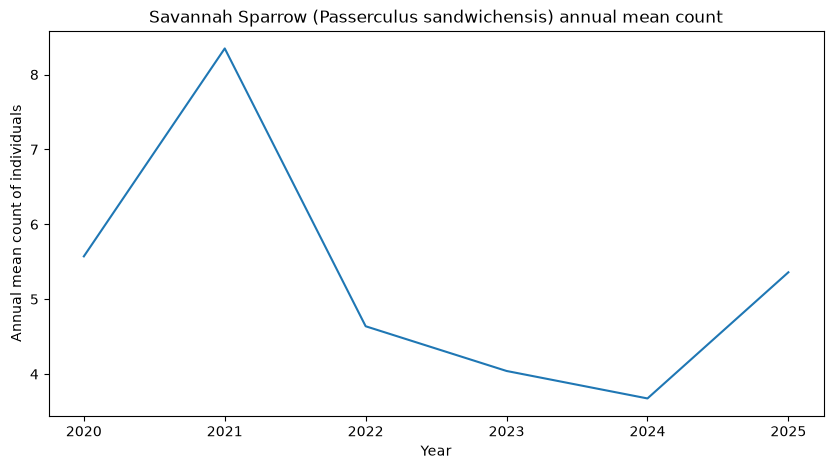

In [14]:
mean_count_df .plot(
        legend=False,
        xlabel="Year",
        ylabel="Annual mean count of individuals",
        figsize=(10, 5),
        title="Savannah Sparrow (Passerculus sandwichensis) annual mean count"
    )

In [ ]:
### ndvi_df is the mean annaul NDVI
ndvi_df

,band,spatial_ref,NDVI
year,,,
2021,1,0,0.597142
2022,1,0,0.532841
2023,1,0,0.529257
2024,1,0,0.622692
2025,1,0,0.543020


In [21]:
### concatenate the individual bird count df and NDVI df
birds_ndvi_df = pd.concat([mean_count_df, ndvi_df["NDVI"]], axis=1)
birds_ndvi_df

,individualCount,NDVI
year,,
2020,5.571429,NaN
2021,8.348315,NaN
2022,4.637931,NaN
2023,4.040816,NaN
2024,3.673913,NaN
2025,5.358974,NaN
2021,NaN,0.597142
2022,NaN,0.532841
2023,NaN,0.529257


In [24]:
### correlation matrix

### Keep paired observations with valid values.
columns = ["individualCount", "NDVI"]
data = birds_ndvi_df[columns].apply(pd.to_numeric, errors = "coerce").dropna()

### Spearman correlation suits skewed bird counts.
### Use method="pearson" to measure a linear relationship instead.
corr = data.corr(method="spearman")
print(f"Paired observations: {len(data)}")
print(corr)


Paired observations: 0
                 individualCount  NDVI
individualCount              NaN   NaN
NDVI                         NaN   NaN


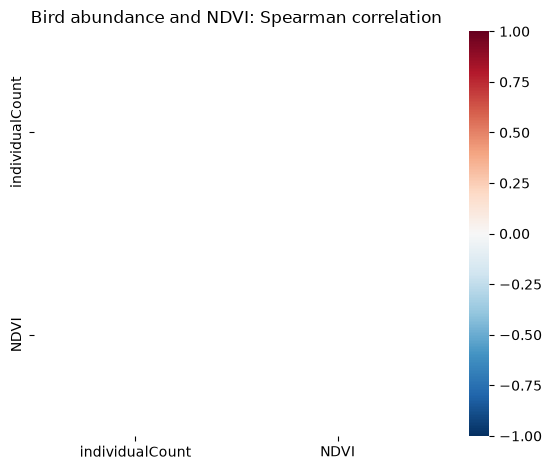

In [25]:
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True,
)
plt.title("Bird abundance and NDVI: Spearman correlation")
plt.tight_layout()
plt.show()
